# Final Project: InspectRank - Prioritizing Chicago Restaurant Inspections

**Course:** ADSP 32021 Machine Learning Operations, University of Chicago M.S. in Applied Data Science  
**Team:** Brooke Rios, John Henry Oliphant, Mpiira Tabuti  
**Repository:** https://github.com/brookerios20/chicago-inspection-ranking-mlops

**Notebook structure**

The notebook follows the four stages of the project brief. Each stage contains subsections named after the course sessions whose tools and ideas it uses.

1. **Part A: Data Ingestion & Baselines** (Sessions 1 and 2): problem framing, data ingestion, versioning, validation, exploratory data analysis and the train/test split
2. **Part B: Pipeline Automation & Experiment Tracking** (Sessions 3 and 4): feature engineering, experiment tracking, AutoML, orchestration and the model registry
3. **Part C: Containerization & Deployment** (Sessions 5, 6 and 7): the prediction API, containerization, explainability, fairness checks and testing
4. **Part D: Production Monitoring & Drift Simulation** (Sessions 7, 8 and 9): monitoring, drift simulation, governance and logging

# A. Data Ingestion & Baselines

### 0. Dependencies, constants, and helpers

In [2]:
# This cell turns on automatic reloading: when a later cell rewrites one of the project's .py files,
# the notebook uses the new version right away, without restarting the kernel.
%load_ext autoreload
%autoreload 2

In [12]:
%%writefile ../config.py
"""Project-wide settings shared by the notebook, the Airflow pipeline and the prediction API.

This file is written by section 0 of the notebook. Keeping every path, date and label rule in
one place avoids the "configuration debt" described in Session 1 (Sculley et al., Hidden
Technical Debt in Machine Learning Systems): a setting changed here is changed everywhere.
"""
from pathlib import Path

import pandas as pd

# Paths (built from this file's location, so they work from any working directory)
PROJECT_DIR = Path(__file__).resolve().parent
DATA_DIR = PROJECT_DIR / "Data"
RAW_CSV = DATA_DIR / "Food_Inspections_20261115.csv"
RAW_PARQUET = DATA_DIR / "inspections_raw.parquet"
CLEAN_PARQUET = DATA_DIR / "inspections_clean.parquet"

# One folder per course session; each holds that session's modules and assets
SESSION_DIRS = {
    "1": PROJECT_DIR / "Session 1 - DevOps to MLOps, CI-CD, basic serving",
    "2": PROJECT_DIR / "Session 2 - Data-centric AI ingestion, versioning, validation, privacy",
    "3": PROJECT_DIR / "Session 3 - Data engineering and ML pipelines",
    "4": PROJECT_DIR / "Session 4 - AutoML, training pipelines and orchestration",
    "5": PROJECT_DIR / "Session 5 - Deployment engineering",
    "6": PROJECT_DIR / "Session 6 - Explainability, fairness, faster inference",
    "7a": PROJECT_DIR / "Session 7a - Testing and deployment testing",
    "7b": PROJECT_DIR / "Session 7b - Monitoring and drift simulation",
    "8": PROJECT_DIR / "Session 8 - Ethics and governance gates",
    "9": PROJECT_DIR / "Session 9 - MLOps in practice",
}

# Reproducibility
SEED = 42

# Label definition: outcome of an inspection
FAIL_RESULTS = ["Fail"]
PASS_RESULTS = ["Pass", "Pass w/ Conditions"]
FACILITY_TYPES = ["restaurant"]    # facility types kept in the data

# Key dates
CODE_CHANGE_DATE = pd.Timestamp("2018-07-01")    # food code overhaul, new violation codes
VAL_START = pd.Timestamp("2024-11-01")           # start of the validation period
TEST_START = pd.Timestamp("2025-11-01")          # start of the held-out test period

Overwriting ../config.py


In [4]:
# This cell imports the libraries used in the notebook and makes the project's own .py files
# importable, by adding the project folder (for config.py) and every session folder to Python's
# search path. Keeping pipeline code in .py files, not only in notebook cells, lets the same code
# be reused later by the Airflow pipeline (Session 4) and the prediction API (Session 5).
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import config

# Make each session folder's modules importable
for folder in config.SESSION_DIRS.values():
    sys.path.insert(0, str(folder))

# Display settings
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

### Session 1: DevOps to MLOps, CI/CD, basic serving

### Session 2: Data-centric AI: ingestion, versioning, validation, privacy

In [5]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/ingest.py"
"""Session 2: load the raw Food Inspections CSV and save it as a typed parquet file.

Ingestion is the first step of the pipeline. Reading the CSV once, fixing the column types and
saving a parquet snapshot means every later step starts from the same data with the same types.
Parquet files are also much smaller and faster to load than CSV files.
"""
import pandas as pd

def load_raw(csv_path):
    """Read the raw CSV with stable column types and snake_case column names."""
    df = pd.read_csv(csv_path, dtype={"License #": "string", "Zip": "string"})
    df.columns = df.columns.str.strip().str.lower()
    df.columns = df.columns.str.replace("#", "no").str.replace(" ", "_")
    df["inspection_date"] = pd.to_datetime(df["inspection_date"], format="%m/%d/%Y")
    return df

def ingest(csv_path, parquet_path):
    """Load the raw CSV and write it to parquet for the next pipeline steps."""
    df = load_raw(csv_path)
    df.to_parquet(parquet_path, index=False)
    return df

Writing ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/ingest.py


In [8]:
# This cell runs the ingestion step: it reads the raw CSV, saves inspections_raw.parquet, and prints
# the number of rows and columns, the date range and the column types as a quick check.
import ingest

raw = ingest.ingest(config.RAW_CSV, config.RAW_PARQUET)
print(raw.shape)
print(raw["inspection_date"].min(), "to", raw["inspection_date"].max())
raw.dtypes

(318396, 17)
2010-01-04 00:00:00 to 2026-11-13 00:00:00


inspection_id               int64
dba_name                   object
aka_name                   object
license_no         string[python]
facility_type              object
risk                       object
address                    object
city                       object
state                      object
zip                string[python]
inspection_date    datetime64[ns]
inspection_type            object
results                    object
violations                 object
latitude                  float64
longitude                 float64
location                   object
dtype: object

In [10]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/clean.py"
"""Session 2: keep inspections with a real outcome, build the 0/1 fail label and tidy columns.

The cleaning rules live in one function, so the training data and any data scored later are
cleaned in exactly the same way. Sessions 2 and 3 warn that differences in how training data
and live data are prepared (training-serving skew) can quietly hurt a model in production.
"""
import pandas as pd

import config

RISK_LEVELS = {"Risk 1 (High)": 1, "Risk 2 (Medium)": 2, "Risk 3 (Low)": 3}

def clean(raw):
    """Return in-scope inspections with a real outcome, a 0/1 fail label and tidy columns."""
    df = raw[raw["results"].isin(config.FAIL_RESULTS + config.PASS_RESULTS)].copy()
    df = df[df["license_no"].notna() & (df["license_no"] != "0")]
    df["facility_type"] = df["facility_type"].str.strip().str.lower()
    df["inspection_type"] = df["inspection_type"].str.strip().str.lower()
    df = df[df["facility_type"].isin(config.FACILITY_TYPES)]
    df["risk_level"] = df["risk"].map(RISK_LEVELS)    # "All" and missing become NaN
    df["fail"] = df["results"].isin(config.FAIL_RESULTS).astype(int)
    return df.sort_values(["license_no", "inspection_date"]).reset_index(drop=True)

def clean_file(raw_path, clean_path):
    """Read the raw parquet, clean it and write the cleaned parquet."""
    df = clean(pd.read_parquet(raw_path))
    df.to_parquet(clean_path, index=False)
    return df

Writing ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/clean.py


In [11]:
# This cell runs the cleaning step on the raw parquet and saves inspections_clean.parquet. It prints
# the number of inspections and restaurants kept, the share that failed, and a count of each result.
import clean

inspections = clean.clean_file(config.RAW_PARQUET, config.CLEAN_PARQUET)
print(inspections.shape)
print("establishments:", inspections["license_no"].nunique())
print("fail rate:", inspections["fail"].mean().round(3))
inspections["results"].value_counts()

(185482, 19)
establishments: 27242
fail rate: 0.217


results
Pass                  109931
Fail                   40174
Pass w/ Conditions     35377
Name: count, dtype: int64

In [13]:
%%writefile "../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/split.py"
"""Session 2: split inspections by date into drift, train, validation and test sets.

Splitting by date (not at random) mirrors how the model is used: it learns from past inspections
and is judged on later ones. The test period stays untouched until the final check, as the project
brief requires. Inspections from before the July 2018 food code change form a separate "drift" set,
used in Part D to check that the monitoring notices when incoming data looks different.
"""
import pandas as pd

import config

SPLITS = ["drift", "train", "val", "test"]

def assign_split(df):
    """Label each inspection by period: before the 2018 code change, train, validation or test."""
    bins = [pd.Timestamp.min, config.CODE_CHANGE_DATE, config.VAL_START,
            config.TEST_START, pd.Timestamp.max]
    out = df.copy()
    out["split"] = pd.cut(out["inspection_date"], bins=bins, right=False, labels=SPLITS)
    return out

def split_file(clean_path, data_dir):
    """Read the cleaned parquet and write one parquet file per split."""
    df = assign_split(pd.read_parquet(clean_path))
    for name in SPLITS:
        df[df["split"] == name].to_parquet(data_dir / f"{name}.parquet", index=False)
    return df

Writing ../Session 2 - Data-centric AI ingestion, versioning, validation, privacy/split.py


In [14]:
# This cell runs the split step, saves one parquet file per period (drift, train, val, test), and
# shows how many inspections fall in each period and the share of them that failed.
import split

inspections = split.split_file(config.CLEAN_PARQUET, config.DATA_DIR)
inspections.groupby("split", observed=True)["fail"].agg(["size", "mean"]).round(3)

,size,mean
split,,
drift,101876,0.210
train,62164,0.229
val,11517,0.210
test,9925,0.209


In [15]:
# This cell sets up DVC (Data Version Control) in the project folder. DVC, covered in Session 2,
# versions data files alongside the code: git keeps small "pointer" files while DVC stores the
# actual data, so any earlier version of a dataset can be traced and recovered later.
# DVC's stored copies go to a folder outside OneDrive, so the large files are not synced to the cloud.
!cd .. && {sys.executable} -m dvc init --subdir
!cd .. && {sys.executable} -m dvc config --local cache.dir C:/Users/mpiir/dvc-cache

Initialized DVC repository.

You can now commit the changes to git.

+---------------------------------------------------------------------+
|                                                                     |
|        DVC has enabled anonymous aggregate usage analytics.         |
|     Read the analytics documentation (and how to opt-out) here:     |
|             <https://dvc.org/doc/user-guide/analytics>              |
|                                                                     |
+---------------------------------------------------------------------+

What's next?
------------
- Check out the documentation: <https://dvc.org/doc>
- Get help and share ideas: <https://dvc.org/chat>
- Star us on GitHub: <https://github.com/treeverse/dvc>


In [21]:
# This cell asks DVC to track the four split files. For each file, DVC saves a copy in its store and
# writes a small pointer file (.dvc) next to it; the pointer file is what gets saved in git.
!cd .. && {sys.executable} -m dvc add Data/drift.parquet Data/train.parquet Data/val.parquet Data/test.parquet

⠋ Checking graph

To track the changes with git, run:



	git add 'Data\drift.parquet.dvc' 'Data\val.parquet.dvc' 'Data\test.parquet.dvc' 'Data\train.parquet.dvc'

To enable auto staging, run:

	dvc config core.autostage true

In [22]:
# This cell saves the DVC setup and pointer files in git and tags the commit "mpiira-data-v1".
# The tag works like a bookmark for this exact version of the data, so a trained model can later be
# linked back to the data it was trained on (data lineage, Session 2).
!cd .. && git add .gitignore .dvcignore .dvc/config .dvc/.gitignore "Data/*.dvc"
!git commit -m "Version data splits with DVC"
!git tag mpiira-data-v1

[main 48a0b8d] Version data splits with DVC
 5 files changed, 22 insertions(+)
 create mode 100644 final_project_mpiira/Data/drift.parquet.dvc
 create mode 100644 final_project_mpiira/Data/test.parquet.dvc
 create mode 100644 final_project_mpiira/Data/train.parquet.dvc
 create mode 100644 final_project_mpiira/Data/val.parquet.dvc


In [23]:
# This cell reads the test set back from the tagged version. It shows that this exact version of the
# data can be recovered later, even if the files on disk change. Being able to reproduce results from
# versioned data and code is a core MLOps practice (Sessions 2 and 9). Only the size of the test set
# is printed; its contents are not explored.
import dvc.api

with dvc.api.open("final_project_mpiira/Data/test.parquet", rev="mpiira-data-v1", mode="rb") as f:
    test_v1 = pd.read_parquet(f)
print(test_v1.shape)

(9925, 20)


### EDA

In [24]:
# This cell loads the training rows and the pre-2018 rows (the drift set) saved by the split step.
# The validation and test files are not opened here, so they stay unseen until the model is evaluated.
BLUE, ORANGE = "#2a78d6", "#eb6834"    # chart colors: blue for 2018 onward, orange for before 2018

train = pd.read_parquet(config.DATA_DIR / "train.parquet")
drift = pd.read_parquet(config.DATA_DIR / "drift.parquet")
print("training inspections:", len(train), "| restaurants:", train["license_no"].nunique())
print("dates:", train["inspection_date"].min().date(), "to", train["inspection_date"].max().date())
print("fail rate:", train["fail"].mean().round(3))
print("\nShare of missing values per column:")
train.isna().mean().round(3).sort_values(ascending=False).head(6)

training inspections: 62164 | restaurants: 14370
dates: 2018-07-03 to 2024-10-31
fail rate: 0.229

Share of missing values per column:


violations    0.144
aka_name      0.001
location      0.001
latitude      0.001
longitude     0.001
license_no    0.000
dtype: float64

median inspections per week: 192


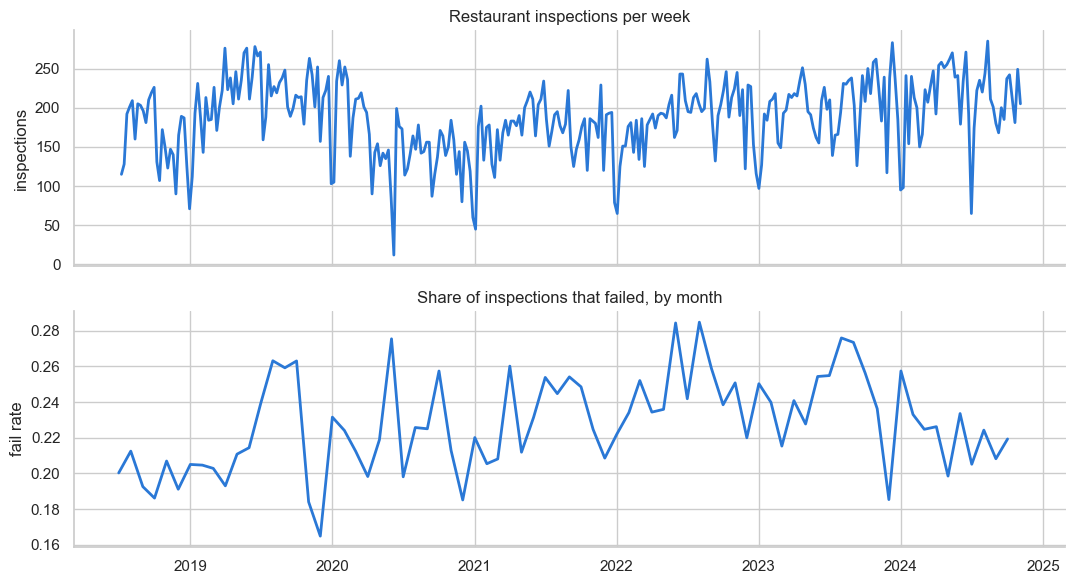

In [25]:
# This cell plots how many restaurant inspections happen each week and how the share of failed
# inspections changes month by month. The weekly count gives a rough idea of how many visits
# inspectors can make, which helps choose k for precision@k.
weekly = train.set_index("inspection_date").resample("W").size()
monthly_fail = train.set_index("inspection_date").resample("MS")["fail"].mean()
print("median inspections per week:", int(weekly.median()))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(weekly.index, weekly.values, color=BLUE, linewidth=2)
axes[0].set_title("Restaurant inspections per week")
axes[0].set_ylabel("inspections")
axes[1].plot(monthly_fail.index, monthly_fail.values, color=BLUE, linewidth=2)
axes[1].set_title("Share of inspections that failed, by month")
axes[1].set_ylabel("fail rate")
sns.despine()
plt.tight_layout()
plt.show()

                          size   mean
inspection_type                      
license re-inspection     2257  0.068
canvass re-inspection     8875  0.095
complaint re-inspection   3487  0.135
short form complaint      1700  0.146
canvass                  30499  0.246
license                   7251  0.293
complaint                 7698  0.366
             size   mean
risk_level              
1.0         52228  0.233
2.0          9325  0.210
3.0           611  0.231


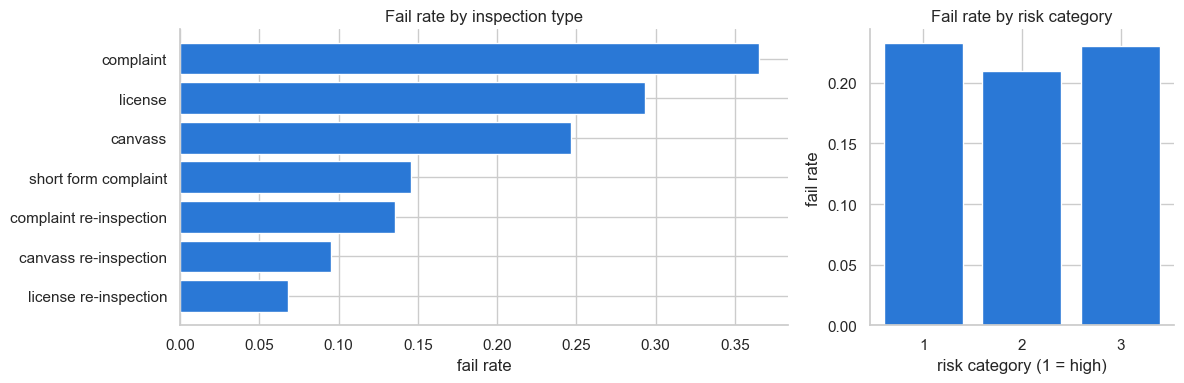

In [26]:
# This cell compares fail rates across inspection types and across the city's risk categories
# (1 = high, 3 = low). Inspection types with fewer than 500 inspections are left out.
by_type = (train.groupby("inspection_type")["fail"].agg(["size", "mean"])
            .query("size >= 500").sort_values("mean"))
by_risk = train.groupby("risk_level")["fail"].agg(["size", "mean"])
print(by_type.round(3))
print(by_risk.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
axes[0].barh(by_type.index, by_type["mean"], color=BLUE)
axes[0].set_title("Fail rate by inspection type")
axes[0].set_xlabel("fail rate")
axes[1].bar(by_risk.index.astype(int).astype(str), by_risk["mean"], color=BLUE)
axes[1].set_title("Fail rate by risk category")
axes[1].set_xlabel("risk category (1 = high)")
axes[1].set_ylabel("fail rate")
sns.despine()
plt.tight_layout()
plt.show()

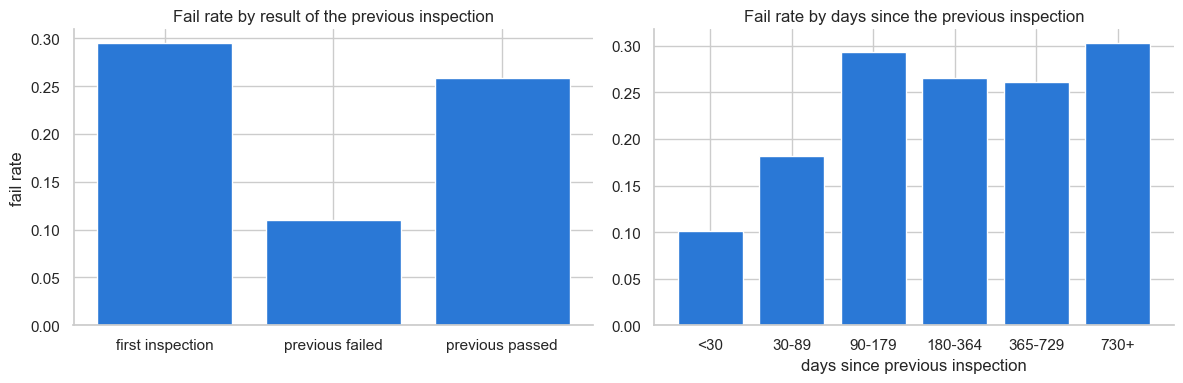

In [27]:
# This cell adds two quick history columns to each inspection: whether the restaurant's previous
# inspection failed, and how many days passed since that previous inspection. Pre-2018 rows are
# included only so that early training inspections can look back at earlier visits.
# These are simple versions for exploration; the full history features are built in Session 3.
history = pd.concat([drift, train]).sort_values(["license_no", "inspection_date"])
by_restaurant = history.groupby("license_no")
history["prev_fail"] = by_restaurant["fail"].shift()
history["days_since_prev"] = by_restaurant["inspection_date"].diff().dt.days
hist_train = history[history["split"] == "train"]

prev_label = hist_train["prev_fail"].map({1: "previous failed", 0: "previous passed"})
by_prev = hist_train.groupby(prev_label.fillna("first inspection"))["fail"].mean()
gap_bins = pd.cut(hist_train["days_since_prev"], [0, 30, 90, 180, 365, 730, np.inf],
                    right=False, labels=["<30", "30-89", "90-179", "180-364", "365-729", "730+"])
by_gap = hist_train.groupby(gap_bins, observed=True)["fail"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(by_prev.index, by_prev.values, color=BLUE)
axes[0].set_title("Fail rate by result of the previous inspection")
axes[0].set_ylabel("fail rate")
axes[1].bar(by_gap.index.astype(str), by_gap.values, color=BLUE)
axes[1].set_title("Fail rate by days since the previous inspection")
axes[1].set_xlabel("days since previous inspection")
sns.despine()
plt.tight_layout()
plt.show()

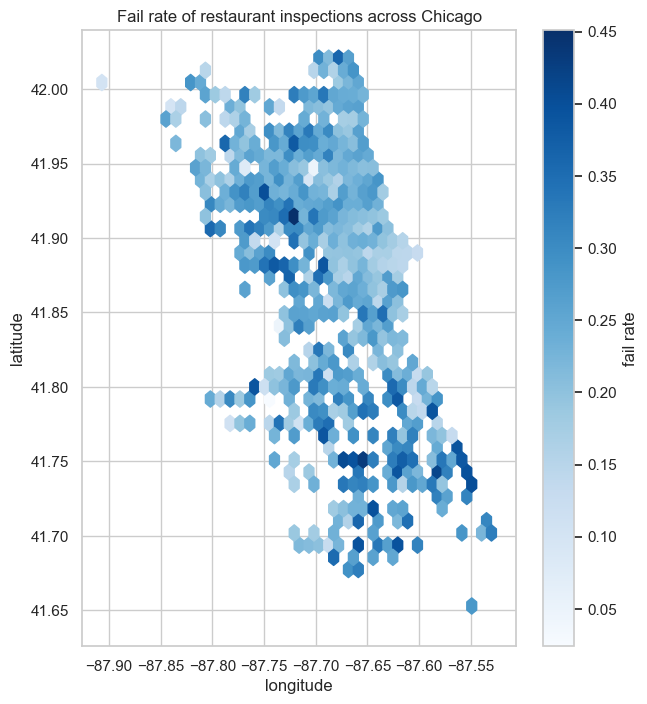

In [28]:
# This cell maps where training inspections took place. Each hexagon covers a small area and is
# shaded by the share of inspections there that failed (darker means a higher fail rate).
# Areas with fewer than 20 inspections are left blank.
geo = train.dropna(subset=["latitude", "longitude"])
fig, ax = plt.subplots(figsize=(7, 8))
hb = ax.hexbin(geo["longitude"], geo["latitude"], C=geo["fail"], reduce_C_function=np.mean,
                gridsize=40, mincnt=20, cmap="Blues")
fig.colorbar(hb, ax=ax, label="fail rate")
ax.set_title("Fail rate of restaurant inspections across Chicago")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
plt.show()

before July 2018: average of 3.59 violations listed per inspection
July 2018 onward: average of 4.72 violations listed per inspection


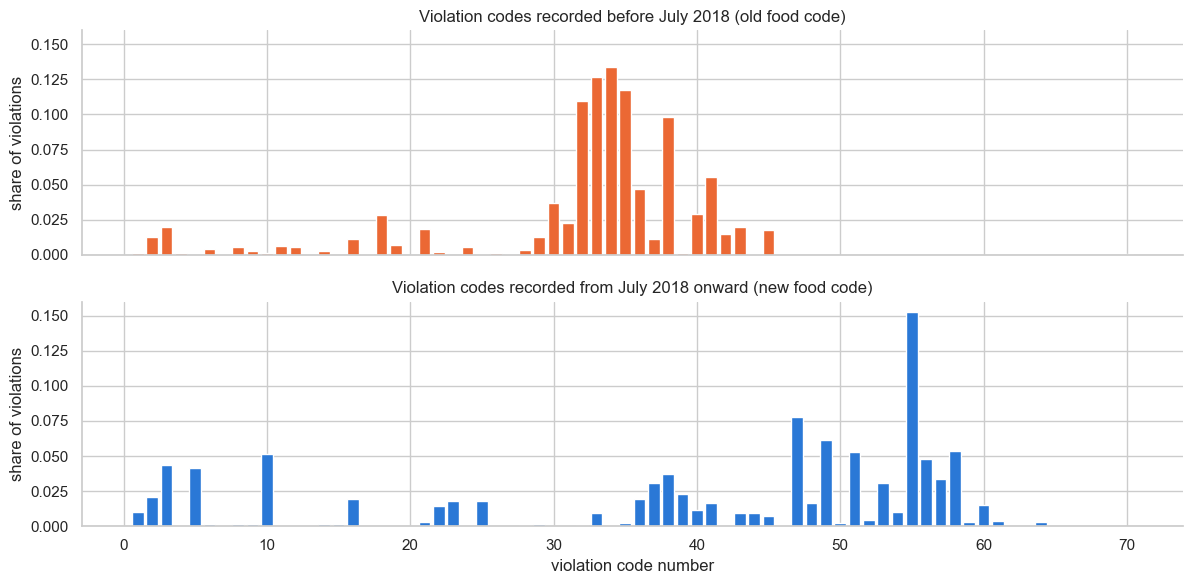

In [29]:
# This cell compares the violation codes recorded before and after the July 2018 food code change.
# Each inspection's violations text lists codes such as "3. MANAGEMENT ... | 5. PROCEDURES ...";
# the code numbers are pulled out and counted. The shift between the two charts is the real
# drift event that the monitoring in Part D should catch.
CODE_PATTERN = r"(?:^|\| )(\d+)\."


def code_shares(df):
    """Return the share of all recorded violations that each violation code makes up."""
    codes = df["violations"].dropna().str.findall(CODE_PATTERN).explode().astype(int)
    return codes.value_counts(normalize=True).sort_index()


before, after = code_shares(drift), code_shares(train)
for name, df in [("before July 2018", drift), ("July 2018 onward", train)]:
    n_codes = df["violations"].fillna("").str.findall(CODE_PATTERN).str.len().mean()
    print(f"{name}: average of {n_codes:.2f} violations listed per inspection")

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
axes[0].bar(before.index, before.values, color=ORANGE)
axes[0].set_title("Violation codes recorded before July 2018 (old food code)")
axes[1].bar(after.index, after.values, color=BLUE)
axes[1].set_title("Violation codes recorded from July 2018 onward (new food code)")
axes[1].set_xlabel("violation code number")
for ax in axes:
    ax.set_ylabel("share of violations")
sns.despine()
plt.tight_layout()
plt.show()